# РК 1. EDA-анализ данных об SQL-инъекциях

Цель анализа — исследовать структуру преподавательского датасета, распределения категорий и типов атак, используемые инструменты, MITRE-техники, теги, источники и текстовые поля, а также выявить основные закономерности.

Чтобы получить `sql_injections_merged.csv` необходимо предварительно запустить `client.py`.

In [72]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv("sql_injections_merged.csv")
df.shape

(14133, 15)

In [73]:
def split_values(series, pattern=r"[,;#]", lower=False):
    values = []
    for value in series.dropna().astype(str):
        for part in re.split(pattern, value):
            token = part.strip()
            if lower:
                token = token.lower()
            if token:
                values.append(token)
    return values


def plot_counter(counter, top_n, title):
    top = pd.Series(dict(counter.most_common(top_n)), dtype="int64")
    if top.empty:
        print("Нет данных для построения графика")
        return top

    plt.figure(figsize=(10, max(5, top_n * 0.32)))
    top.sort_values().plot(kind="barh")
    plt.title(title)
    plt.xlabel("Количество")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()
    return top


def pct(part, whole):
    return 0.0 if whole == 0 else 100 * part / whole


def fmt_int(value):
    return f"{int(value):,}".replace(",", " ")

## 1. Общая информация: размер, типы, пропуски и дубликаты

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14133 entries, 0 to 14132
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   id                    14133 non-null  int64 
 1   title                 14133 non-null  object
 2   category              14133 non-null  object
 3   attack_type           14133 non-null  object
 4   scenario_description  14133 non-null  object
 5   attack_steps          14133 non-null  object
 6   tools_used            14119 non-null  object
 7   target_type           14129 non-null  object
 8   vulnerability         14115 non-null  object
 9   mitre_technique       14109 non-null  object
 10  impact                14130 non-null  object
 11  detection_method      14129 non-null  object
 12  solution              14130 non-null  object
 13  tags                  14130 non-null  object
 14  source                13973 non-null  object
dtypes: int64(1), object(14)
memory usage

,missing,pct
source,160,1.13
mitre_technique,24,0.17
vulnerability,18,0.13
tools_used,14,0.10
target_type,4,0.03
detection_method,4,0.03
impact,3,0.02
solution,3,0.02
tags,3,0.02


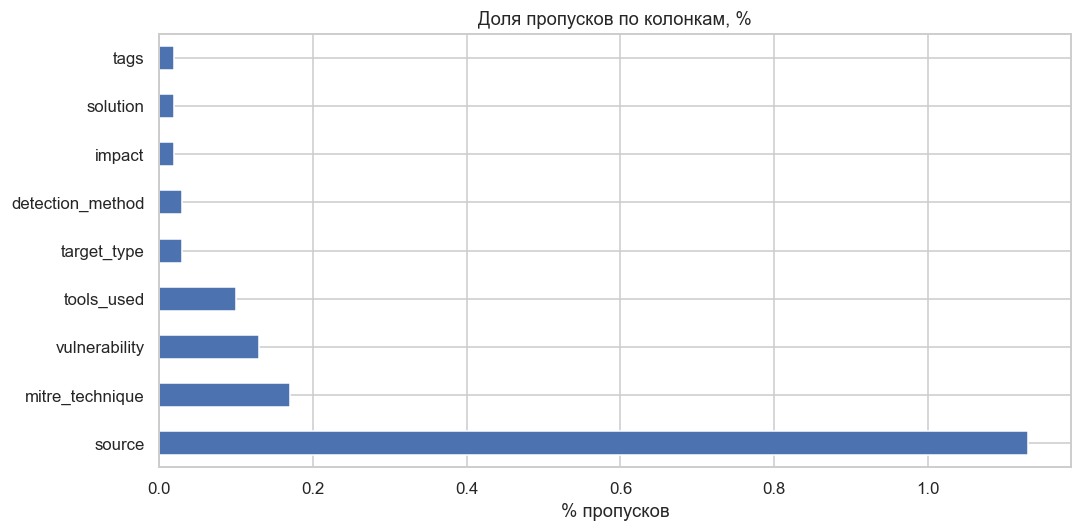

In [74]:
df.info()
print("Дубликаты по id:", df["id"].duplicated().sum())
print("Полные дубликаты:", df.duplicated().sum())

missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"missing": missing, "pct": missing_pct})
missing_df = missing_df[missing_df["missing"] > 0]
display(missing_df)

missing_pct[missing_pct > 0].plot(kind="barh", title="Доля пропусков по колонкам, %")
plt.xlabel("% пропусков")
plt.tight_layout()
plt.show()

## 2. Анализ `Category`

category
Insider Threat                                 569
Physical / Hardware Attacks                    548
Quantum Cryptography & Post-Quantum Threats    542
Wireless Attacks (Advanced)                    535
Malware & Threat                               528
Satellite & Space Infrastructure Security      515
DFIR                                           510
Red Team                                       503
Blockchain / Web3                              503
Blue Team                                      503
Name: count, dtype: int64

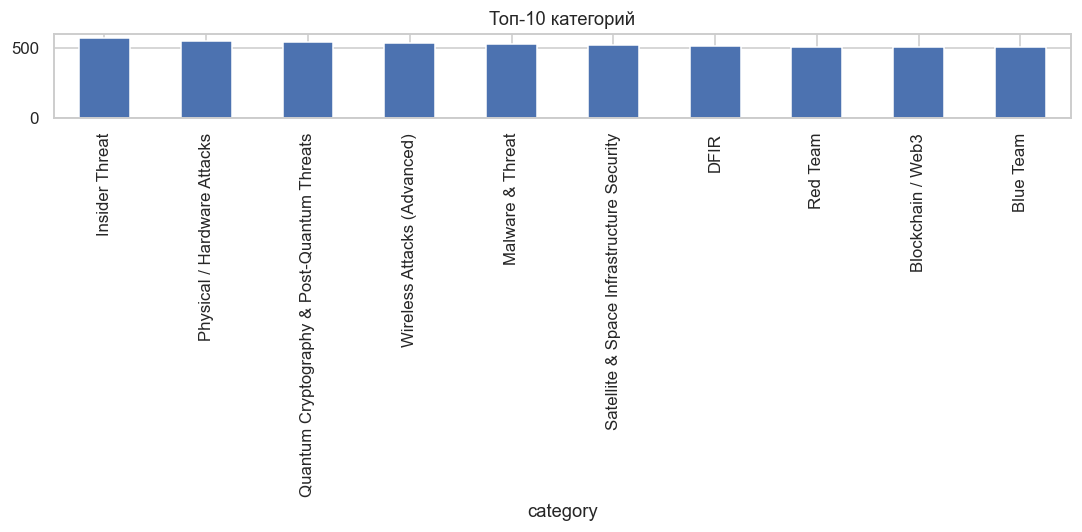

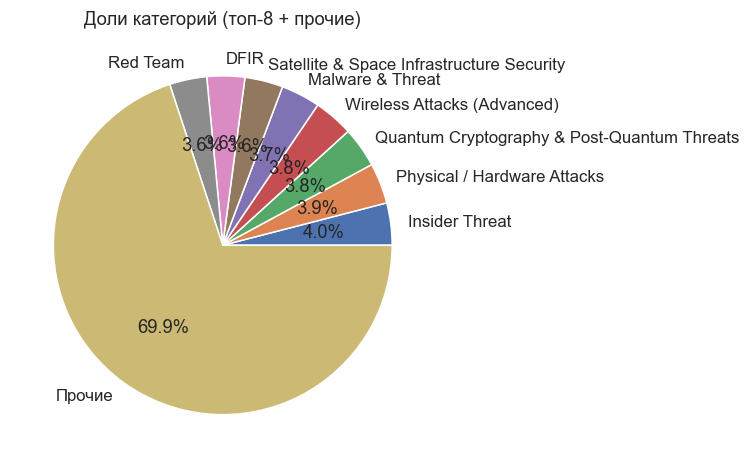

In [75]:
top10 = df["category"].value_counts().head(10)
display(top10)

top10.plot(kind="bar", title="Топ-10 категорий")
plt.tight_layout()
plt.show()

top8 = df["category"].value_counts().head(8)
other = df["category"].value_counts().iloc[8:].sum()
pie_data = pd.concat([top8, pd.Series({"Прочие": other})])
pie_data.plot(kind="pie", autopct="%1.1f%%", title="Доли категорий (топ-8 + прочие)")
plt.ylabel("")
plt.show()

## 3. Анализ `Attack Type`

attack_type
Hardware Interface Exploitation    161
Wireless Attacks (Advanced)         95
Dependency Confusion                91
Fuzzer Configuration                75
Malicious Libraries                 74
Malicious Library                   71
Privilege Escalation                61
Removable Media Attack              55
Misuse of Legitimate Tools          55
Stuxnet-Style PLC Rootkit           52
Name: count, dtype: int64

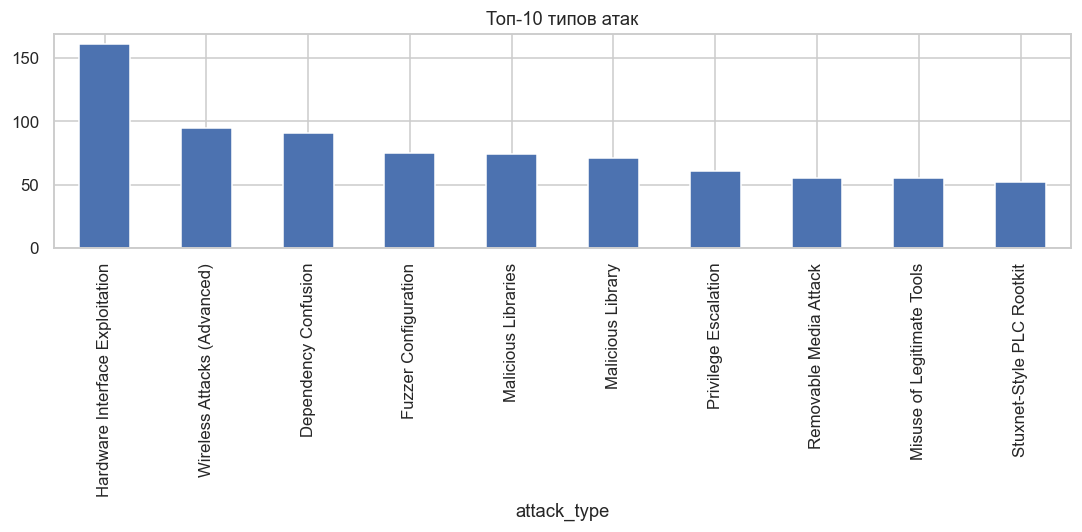

Уникальных типов: 8834


In [76]:
at = df["attack_type"].value_counts()
display(at.head(10))
at.head(10).plot(kind="bar", title="Топ-10 типов атак")
plt.tight_layout()
plt.show()

print("Уникальных типов:", df["attack_type"].nunique())

## 4. Анализ `Tools Used`

burp suite    1118
wireshark      714
curl           540
python         510
bash           400
postman        289
scapy          271
powershell     269
browser        244
nmap           214
netcat         205
pytorch        190
ghidra         184
afl++          184
github         180
dtype: int64

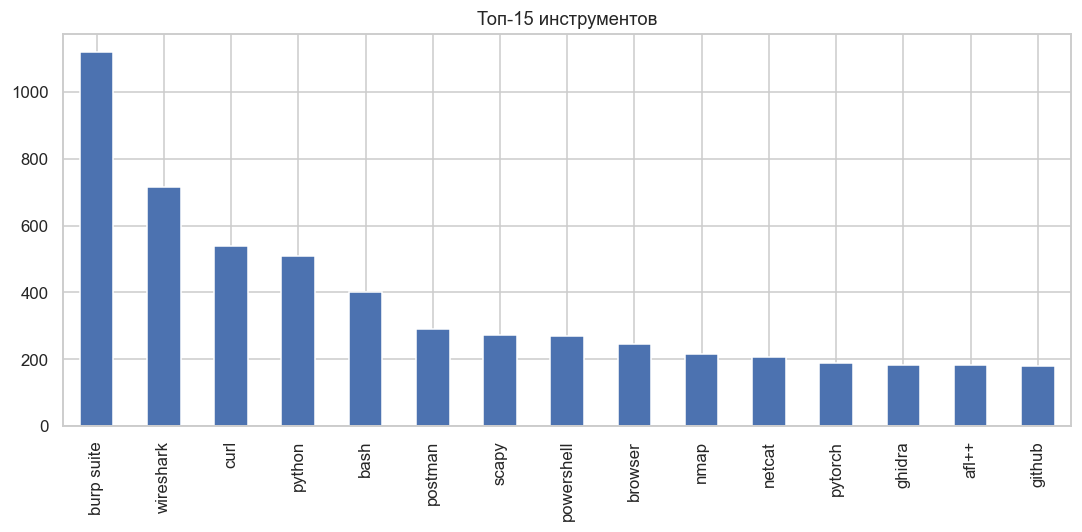

In [77]:
def split_multi(value, pattern=r"[,;#]"):
    if pd.isna(value):
        return []
    return [v.strip().lower() for v in re.split(pattern, str(value)) if v.strip()]

tools = Counter()
for v in df["tools_used"].dropna():
    tools.update(split_multi(v))

tools_top = pd.Series(dict(tools.most_common(15)))
display(tools_top)
tools_top.plot(kind="bar", title="Топ-15 инструментов")
plt.tight_layout()
plt.show()

## 5. Анализ `MITRE Technique`

T1203        740
T1499        401
T1606        352
T1552.001    302
T1040        280
T1557        280
T1609        271
T1600        259
T1059        239
T1204.002    235
dtype: int64

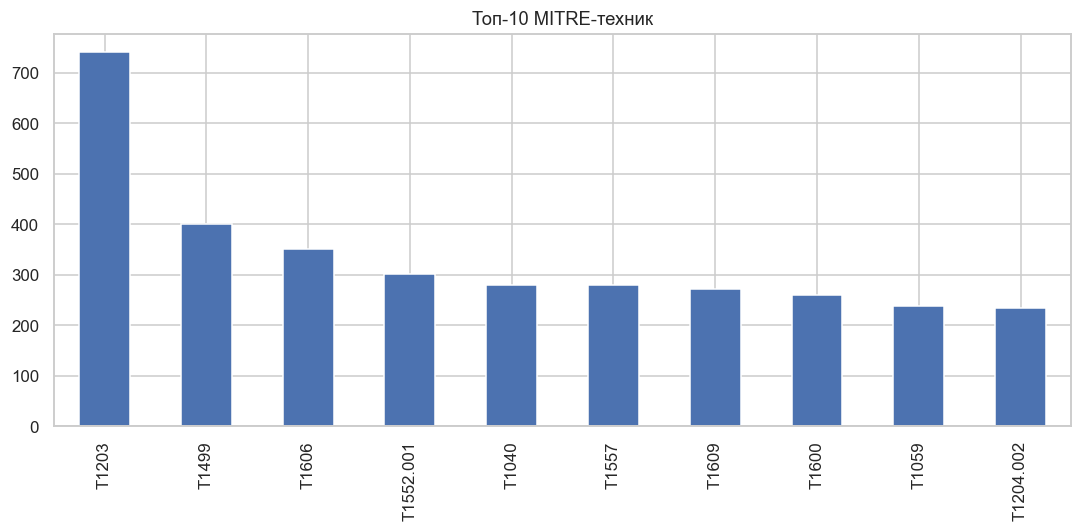

In [78]:
def extract_mitre(value):
    if pd.isna(value):
        return []
    return re.findall(r"T\d{4}(?:\.\d{3})?", str(value))

mitre = Counter()
for v in df["mitre_technique"].dropna():
    mitre.update(extract_mitre(v))

mitre_top = pd.Series(dict(mitre.most_common(10)))
display(mitre_top)
mitre_top.plot(kind="bar", title="Топ-10 MITRE-техник")
plt.tight_layout()
plt.show()

## 6. Анализ `Tags`

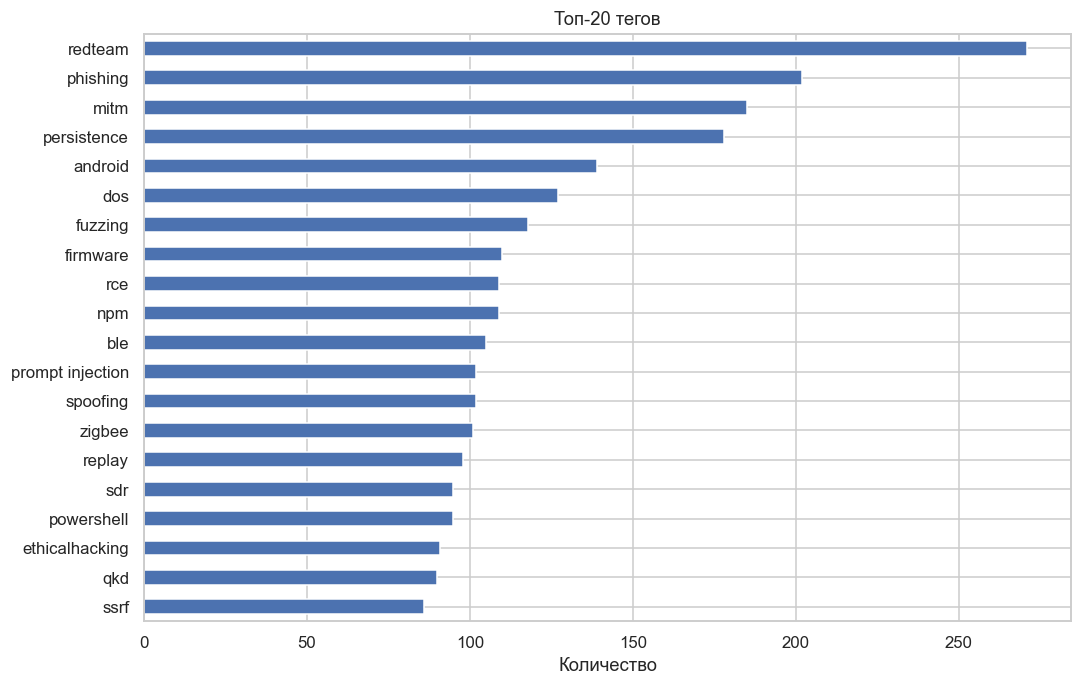

,count
redteam,271
phishing,202
mitm,185
persistence,178
android,139
dos,127
fuzzing,118
firmware,110
rce,109
npm,109


Вывод: наиболее частые теги — redteam (271), phishing (202), mitm (185), persistence (178), android (139).
Лидирующие теги `redteam`, `phishing`, `mitm`, `persistence` и `android` показывают, что в наборе заметно представлены как наступательные сценарии, так и сетевые, социальные и платформенные аспекты атак.


In [79]:
tags = split_values(df["tags"], pattern=r"[,;#]", lower=True)
tags_counter = Counter(tags)
top_tags = plot_counter(tags_counter, 20, "Топ-20 тегов")
display(top_tags.sort_values(ascending=False).to_frame("count"))

top5_tags = tags_counter.most_common(5)
print(
    "Вывод: наиболее частые теги — "
    + ", ".join(f"{name} ({count})" for name, count in top5_tags)
    + "."
)
print(
    "Лидирующие теги `redteam`, `phishing`, `mitm`, `persistence` и `android` показывают, "
    "что в наборе заметно представлены как наступательные сценарии, так и сетевые, социальные и платформенные аспекты атак."
)

## 7. Анализ `Source`

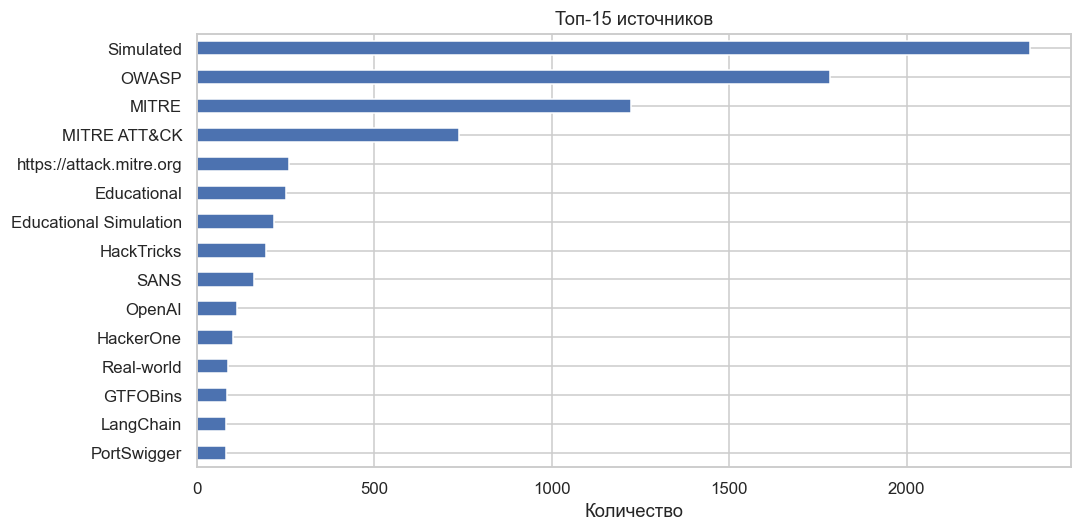

,count
Simulated,2347
OWASP,1783
MITRE,1225
MITRE ATT&CK,738
https://attack.mitre.org,259
Educational,251
Educational Simulation,219
HackTricks,194
SANS,163
OpenAI,114


Вывод: наиболее часто встречаются источники/обозначения Simulated (2347), OWASP (1783), MITRE (1225), MITRE ATT&CK (738), https://attack.mitre.org (259).
По частоте лидирует `Simulated`. Среди явно именованных отраслевых источников особенно заметны OWASP, MITRE и MITRE ATT&CK, которые формируют существенную часть ссылочной базы датасета.


In [80]:
sources = split_values(df["source"], pattern=r"[,;]")
sources_counter = Counter(sources)
top_sources = plot_counter(sources_counter, 15, "Топ-15 источников")
display(top_sources.sort_values(ascending=False).to_frame("count"))

top5_sources = sources_counter.most_common(5)
print(
    "Вывод: наиболее часто встречаются источники/обозначения "
    + ", ".join(f"{name} ({count})" for name, count in top5_sources)
    + "."
)
print(
    "По частоте лидирует `Simulated`. Среди явно именованных отраслевых источников особенно заметны OWASP, MITRE и MITRE ATT&CK, "
    "которые формируют существенную часть ссылочной базы датасета."
)

## 8. `Category × Attack Type`

attack_type,Hardware Interface Exploitation,Misuse of Legitimate Tools,Privilege Escalation,Removable Media Attack,Wireless Attacks (Advanced)
category,,,,,
Blue Team,0,0,3,0,0
DFIR,0,0,1,0,0
Insider Threat,0,55,45,0,0
Physical / Hardware Attacks,161,0,0,55,0
Quantum Cryptography & Post-Quantum Threats,0,0,0,0,95
Red Team,0,0,2,0,0


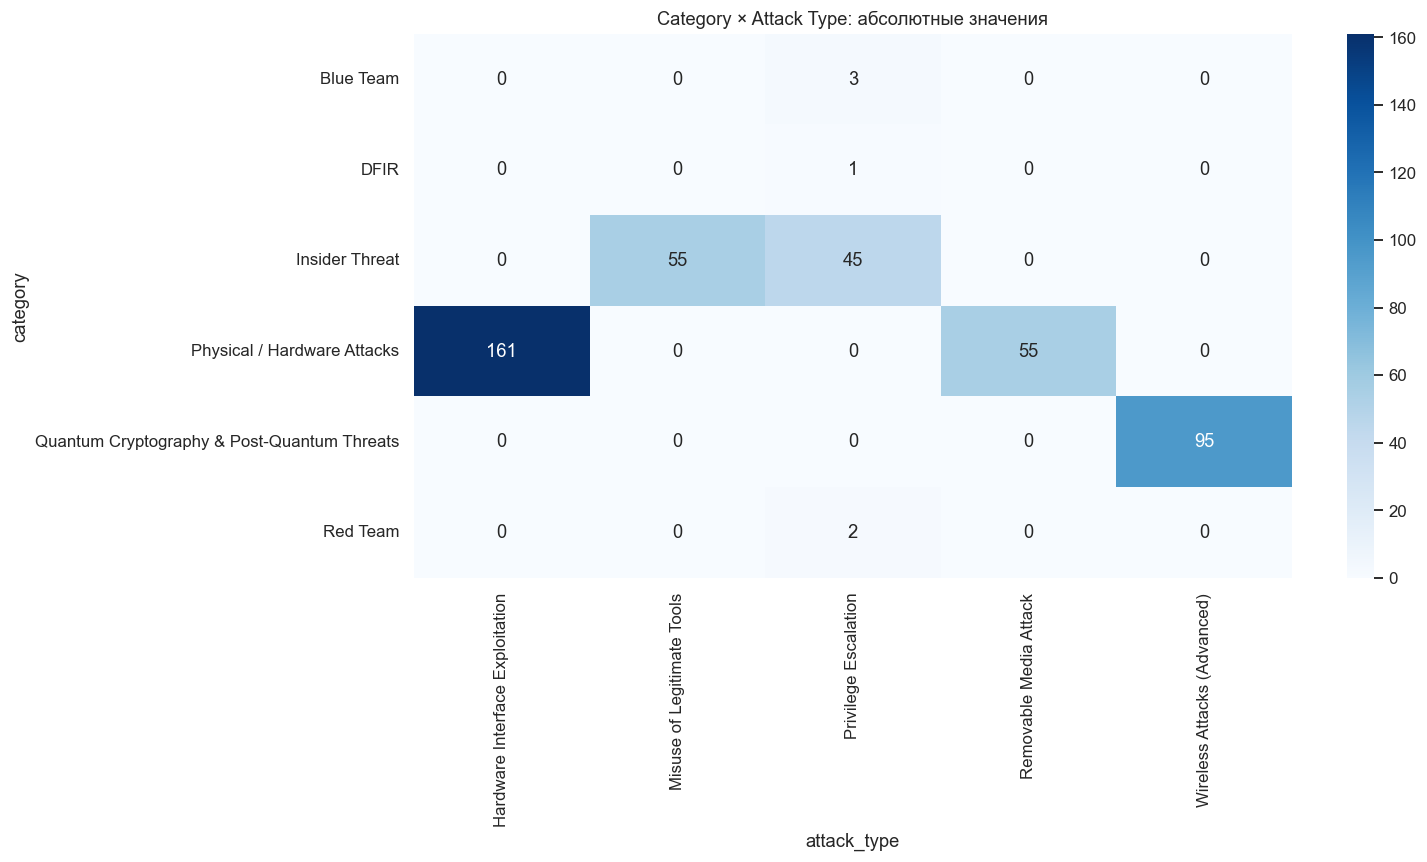

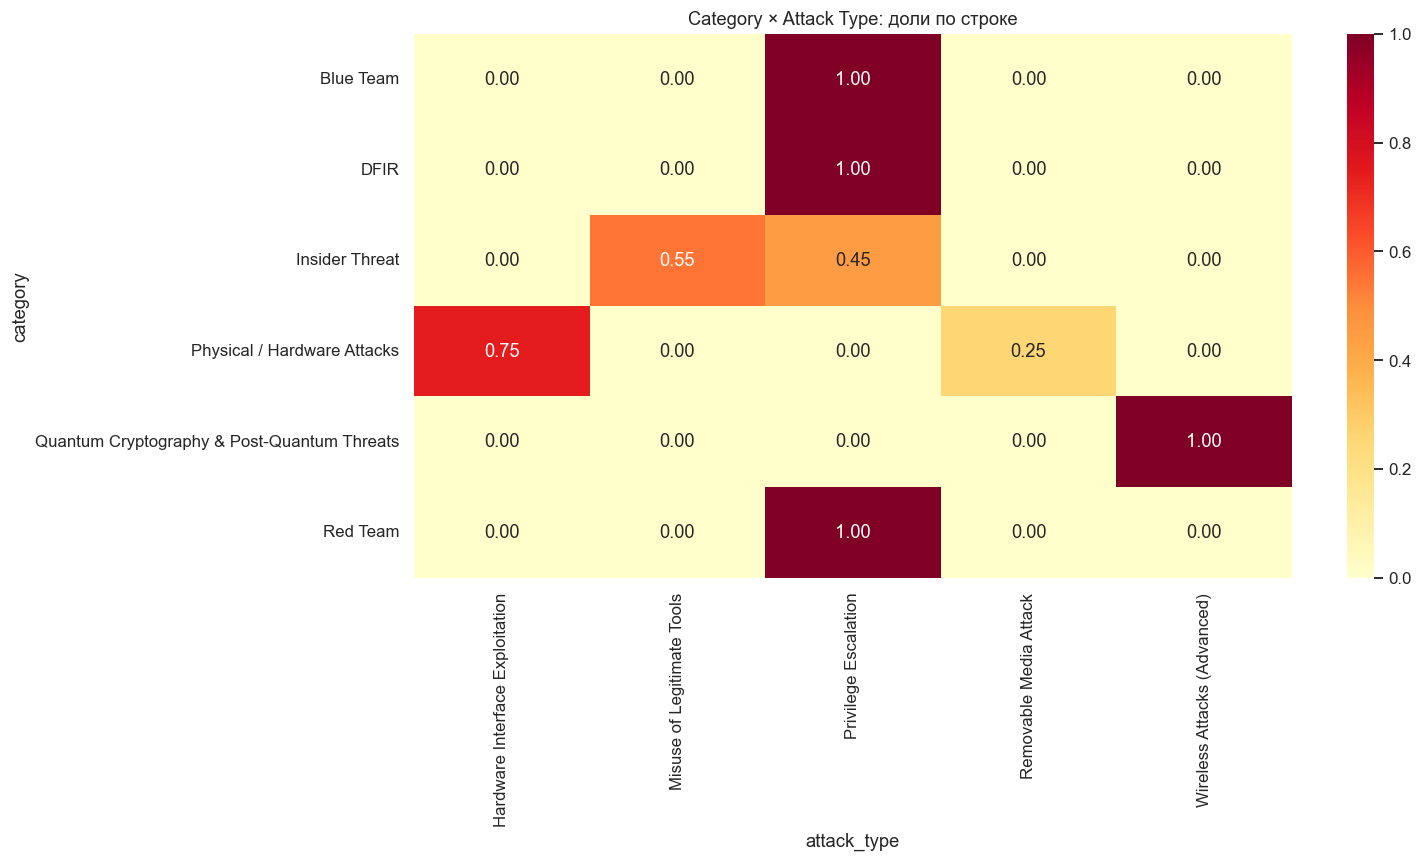

Вывод: наиболее выраженная пара — 'Physical / Hardware Attacks' → 'Hardware Interface Exploitation', частота — 161. В строке этой категории внутри матрицы топ-10 данный тип составляет 74.54%.
Следовательно, между отдельными категориями и типами атак присутствуют выраженные частотные связи; абсолютная и нормированная heatmap позволяют увидеть их с разных сторон.


In [81]:
top_categories = df["category"].value_counts().head(10).index
top_attacks = df["attack_type"].value_counts().head(10).index

subset = df[
    df["category"].isin(top_categories)
    & df["attack_type"].isin(top_attacks)
]

ct_cat_attack = pd.crosstab(subset["category"], subset["attack_type"])
display(ct_cat_attack)

plt.figure(figsize=(14, 8))
sns.heatmap(ct_cat_attack, annot=True, fmt="d", cmap="Blues")
plt.title("Category × Attack Type: абсолютные значения")
plt.tight_layout()
plt.show()

row_share = ct_cat_attack.div(ct_cat_attack.sum(axis=1).replace(0, np.nan), axis=0)

plt.figure(figsize=(14, 8))
sns.heatmap(row_share, annot=True, fmt=".2f", cmap="YlOrRd")
plt.title("Category × Attack Type: доли по строке")
plt.tight_layout()
plt.show()

if not ct_cat_attack.empty:
    strongest = ct_cat_attack.stack().sort_values(ascending=False)
    pair = strongest.index[0]
    count = int(strongest.iloc[0])
    pair_share = float(row_share.loc[pair[0], pair[1]])

    print(
        f"Вывод: наиболее выраженная пара — '{pair[0]}' → '{pair[1]}', частота — {count}. "
        f"В строке этой категории внутри матрицы топ-10 данный тип составляет {pair_share:.2%}."
    )
    print(
        "Следовательно, между отдельными категориями и типами атак присутствуют выраженные частотные связи; "
        "абсолютная и нормированная heatmap позволяют увидеть их с разных сторон."
    )

## 9. `Attack Type × MITRE`

mitre_main,T1040,T1203,T1204.002,T1499,T1552.001,T1557,T1600
attack_type,,,,,,,
Dependency Confusion,0,1,0,0,0,1,0
Fuzzer Configuration,0,21,0,10,0,0,0
Hardware Interface Exploitation,10,3,7,1,1,2,20
Malicious Libraries,0,5,6,1,1,0,0
Malicious Library,2,6,0,1,1,0,0
Privilege Escalation,0,0,0,0,2,0,0
Removable Media Attack,4,1,3,2,0,0,0
Wireless Attacks (Advanced),6,3,0,1,1,2,9


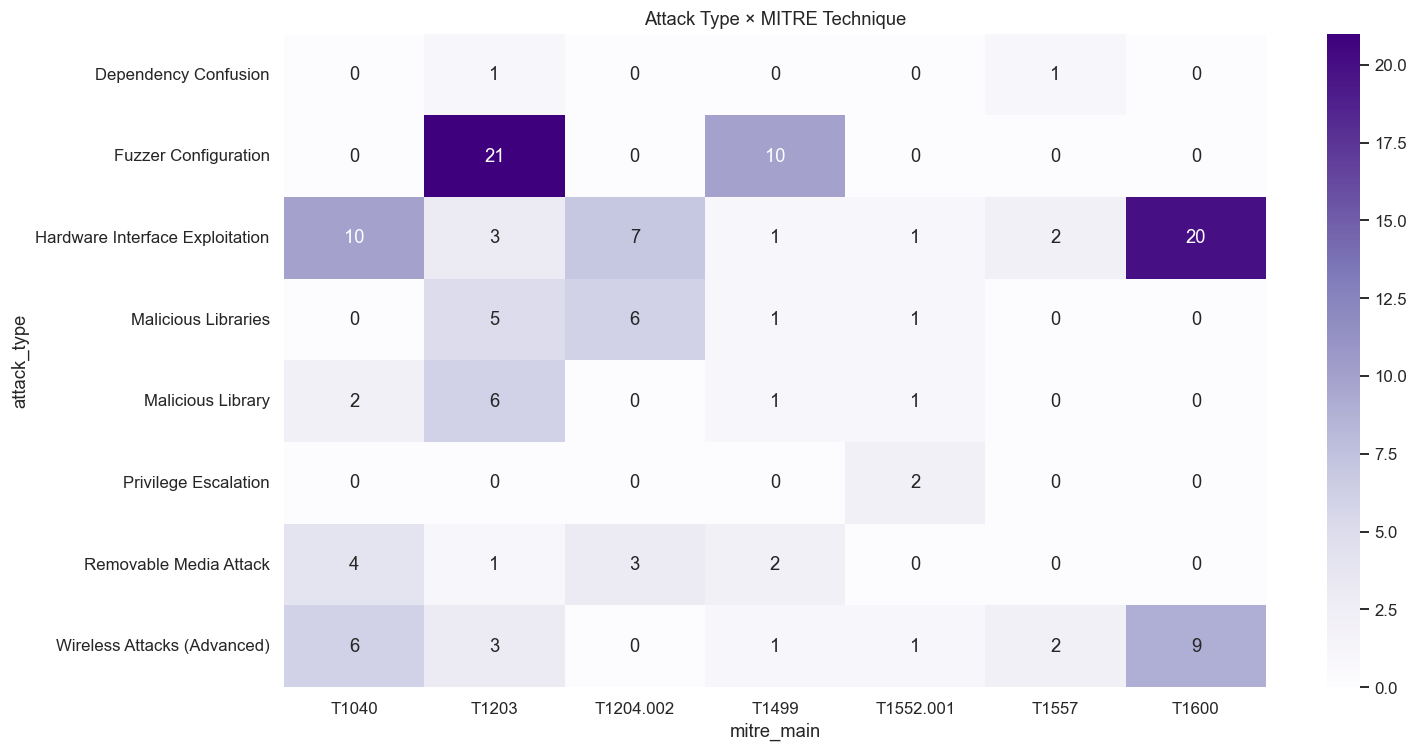

Вывод: наиболее выраженная связь в выбранной матрице — 'Fuzzer Configuration' с техникой T1203 (21 записей).
Тепловая карта показывает, что одни и те же MITRE-техники могут встречаться у разных `Attack Type`, но для отдельных типов атак формируются заметные локальные максимумы.


In [82]:
def first_mitre(value):
    mitre_pattern = r"T\d{4}(?:\.\d{3})?"
    if pd.isna(value):
        return np.nan
    found = re.findall(mitre_pattern, str(value))
    return found[0] if found else np.nan


df["mitre_main"] = df["mitre_technique"].apply(first_mitre)

top8_attack = df["attack_type"].value_counts().head(8).index
top10_mitre = df["mitre_main"].value_counts().head(10).index

subset = df[
    df["attack_type"].isin(top8_attack)
    & df["mitre_main"].isin(top10_mitre)
]

ct_attack_mitre = pd.crosstab(subset["attack_type"], subset["mitre_main"])
display(ct_attack_mitre)

plt.figure(figsize=(14, 7))
sns.heatmap(ct_attack_mitre, annot=True, fmt="d", cmap="Purples")
plt.title("Attack Type × MITRE Technique")
plt.tight_layout()
plt.show()

if not ct_attack_mitre.empty:
    strongest = ct_attack_mitre.stack().sort_values(ascending=False)
    pair = strongest.index[0]
    count = int(strongest.iloc[0])

    print(
        f"Вывод: наиболее выраженная связь в выбранной матрице — '{pair[0]}' с техникой {pair[1]} "
        f"({count} записей)."
    )
    print(
        "Тепловая карта показывает, что одни и те же MITRE-техники могут встречаться у разных `Attack Type`, "
        "но для отдельных типов атак формируются заметные локальные максимумы."
    )

## 10. Длины текстовых полей

,len_scenario_description,len_attack_steps,len_solution
count,14133.0,14133.0,14133.0
mean,127.6,698.1,63.0
std,90.9,464.7,38.0
min,30.0,23.0,0.0
25%,79.0,387.0,38.0
50%,103.0,554.0,50.0
75%,143.0,890.0,83.0
max,795.0,6003.0,520.0


,mean,median,max,iqr_outliers
field,,,,
scenario_description,127.6,103.0,795,891
attack_steps,698.1,554.0,6003,652
solution,63.0,50.0,520,396


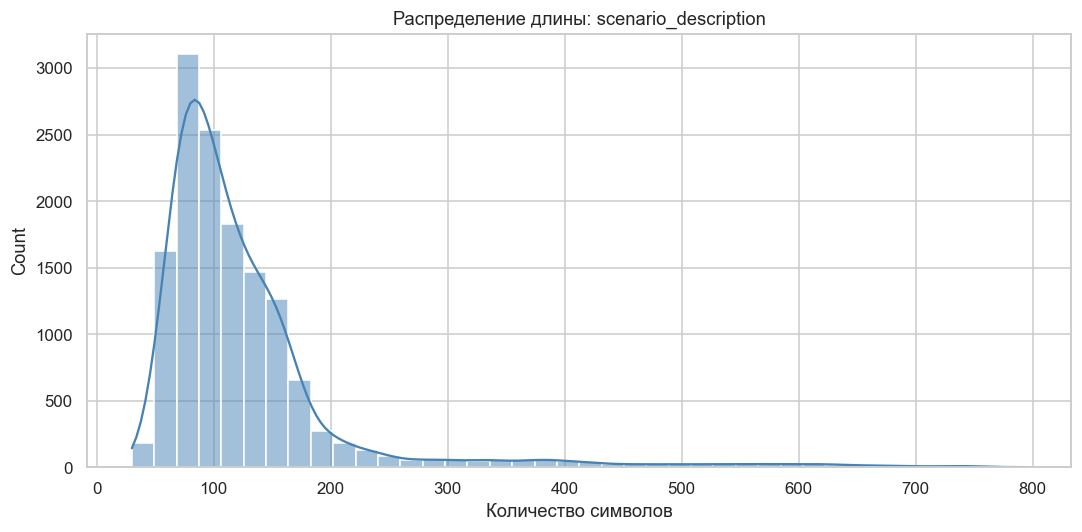

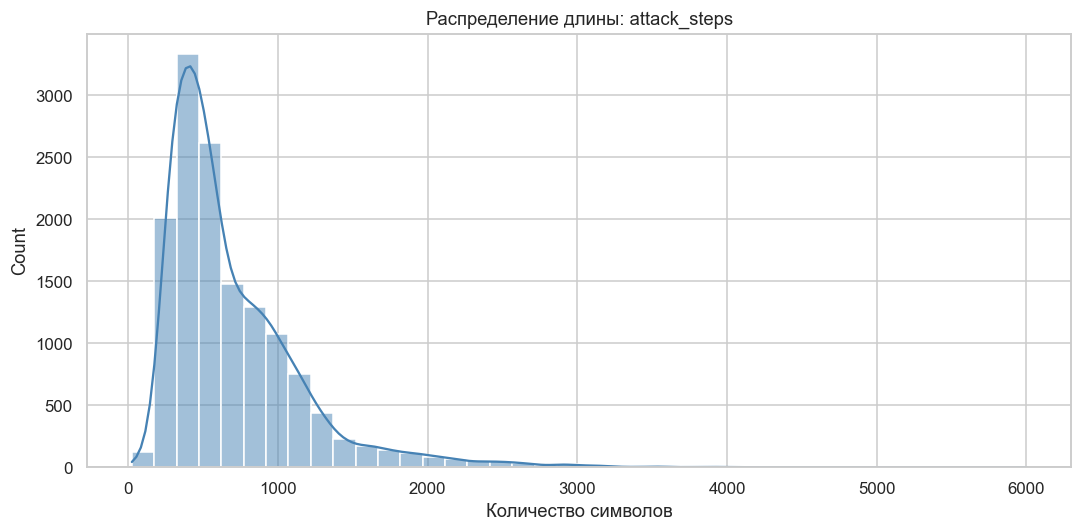

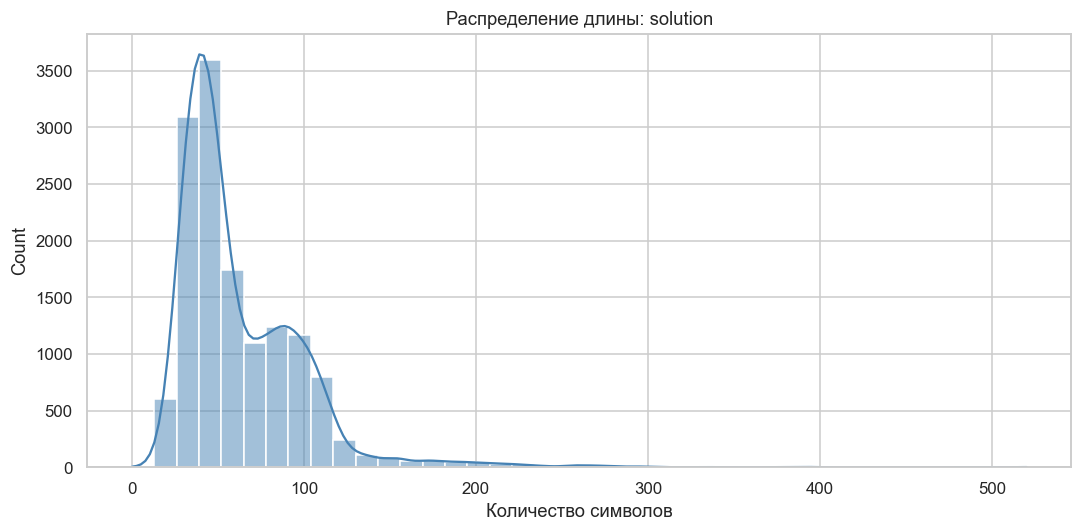

Вывод: самым длинным текстовым полем является `Attack Steps`: средняя длина 698.1, медиана 554.0, максимум 6 003 символов.
Выбросы по правилу 1.5×IQR присутствуют во всех трёх распределениях; это отражает наличие записей с существенно более подробными описаниями, шагами атаки или рекомендациями по защите.


In [83]:
text_columns = {
    "scenario_description": "len_scenario_description",
    "attack_steps": "len_attack_steps",
    "solution": "len_solution",
}

for source_col, length_col in text_columns.items():
    df[length_col] = df[source_col].fillna("").astype(str).str.len()

length_cols = list(text_columns.values())
display(df[length_cols].describe().round(1))

outlier_rows = []
for source_col, length_col in text_columns.items():
    values = df[length_col]
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = int(((values < lower) | (values > upper)).sum())
    outlier_rows.append({
        "field": source_col,
        "mean": round(values.mean(), 1),
        "median": round(values.median(), 1),
        "max": int(values.max()),
        "iqr_outliers": outliers,
    })

outlier_table = pd.DataFrame(outlier_rows).set_index("field")
display(outlier_table)

for source_col, length_col in text_columns.items():
    plt.figure(figsize=(10, 5))
    sns.histplot(x=df[length_col], bins=40, kde=True, color="steelblue")
    plt.title(f"Распределение длины: {source_col}")
    plt.xlabel("Количество символов")
    plt.tight_layout()
    plt.show()

means = df[length_cols].mean().sort_values(ascending=False)
longest = means.index[0]
source_longest = {v: k for k, v in text_columns.items()}[longest]

print(
    f"Вывод: самым длинным текстовым полем является `Attack Steps`: средняя длина {df['len_attack_steps'].mean():.1f}, "
    f"медиана {df['len_attack_steps'].median():.1f}, максимум {fmt_int(df['len_attack_steps'].max())} символов."
)
print(
    "Выбросы по правилу 1.5×IQR присутствуют во всех трёх распределениях; это отражает наличие записей "
    "с существенно более подробными описаниями, шагами атаки или рекомендациями по защите."
)

## 11. Частые слова в `Solution`

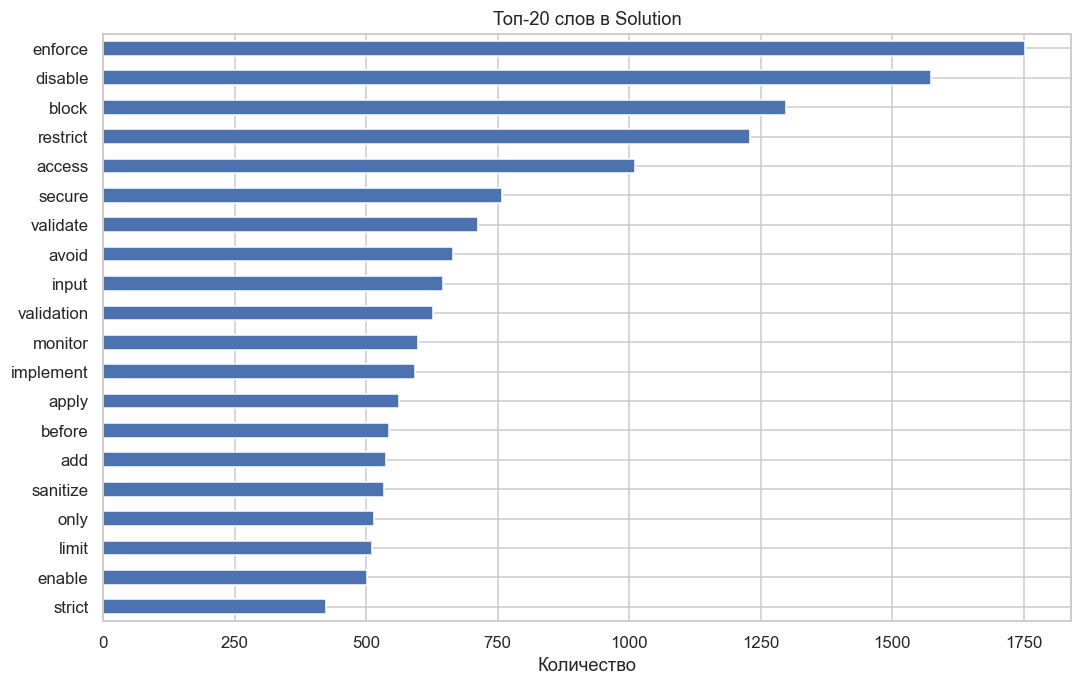

,count
enforce,1753
disable,1573
block,1298
restrict,1229
access,1011
secure,758
validate,712
avoid,666
input,647
validation,628


Вывод: наиболее частая лексика рекомендаций — enforce (1753), disable (1573), block (1298), restrict (1229), access (1011), secure (758), validate (712), avoid (666), input (647), validation (628).
По смыслу наиболее частые рекомендации сосредоточены вокруг ограничения доступа, блокирования/отключения опасных возможностей, усиления защиты, проверки и валидации входных данных, а также мониторинга.


In [84]:
STOP_WORDS = {
    "the", "a", "an", "and", "or", "of", "to", "in", "for", "on", "with", "by", "from",
    "is", "are", "be", "as", "at", "that", "this", "these", "those", "it", "its", "into",
    "can", "should", "would", "could", "such", "using", "use", "used", "ensure", "all",
    "your", "their", "they", "you", "we", "not", "if", "when", "where", "which", "who",
    "application", "applications", "system", "systems", "data"
}

solution_words = []
for text in df["solution"].dropna().astype(str):
    tokens = re.findall(r"[A-Za-z][A-Za-z\-]+", text.lower())
    solution_words.extend(
        token for token in tokens
        if token not in STOP_WORDS and len(token) > 2
    )

solution_counter = Counter(solution_words)
top_solution = plot_counter(solution_counter, 20, "Топ-20 слов в Solution")
display(top_solution.sort_values(ascending=False).to_frame("count"))

top10_solution = solution_counter.most_common(10)
print(
    "Вывод: наиболее частая лексика рекомендаций — "
    + ", ".join(f"{name} ({count})" for name, count in top10_solution)
    + "."
)
print(
    "По смыслу наиболее частые рекомендации сосредоточены вокруг ограничения доступа, блокирования/отключения опасных возможностей, "
    "усиления защиты, проверки и валидации входных данных, а также мониторинга."
)

## 12. Финальная сводка по исходным полям

In [85]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(dropna=True),
})
display(summary)

original_df = df.iloc[:, :15]
print(f"Вывод: итоговый набор содержит {len(df):,} строк. Category включает {df['category'].nunique()} уникальных значений, Attack Type — {df['attack_type'].nunique()}, а mitre_main — {df['mitre_main'].nunique()} уникальных кодов.")
print(f"Качество заполнения высокое: суммарная доля пропусков в исходных 15 полях составляет {original_df.isna().sum().sum() / original_df.size * 100:.2f}%, полных дубликатов — {original_df.duplicated().sum()}.")

,dtype,non_null,missing,missing_%,unique
id,int64,14133,0,0.00,14133
title,object,14133,0,0.00,13793
category,object,14133,0,0.00,64
attack_type,object,14133,0,0.00,8834
scenario_description,object,14133,0,0.00,13866
attack_steps,object,14133,0,0.00,13895
tools_used,object,14119,14,0.10,12935
target_type,object,14129,4,0.03,9885
vulnerability,object,14115,18,0.13,13424
mitre_technique,object,14109,24,0.17,5770


Вывод: итоговый набор содержит 14,133 строк. Category включает 64 уникальных значений, Attack Type — 8834, а mitre_main — 754 уникальных кодов.
Качество заполнения высокое: суммарная доля пропусков в исходных 15 полях составляет 0.11%, полных дубликатов — 0.


## Финальные выводы

In [86]:
main_categories = df["category"].value_counts().head(3)
main_attacks = df["attack_type"].value_counts().head(3)
tools_counter = Counter(tools)
main_tools = tools_counter.most_common(5)
mitre_pattern = r"T\d{4}(?:\.\d{3})?"
mitre_all = []

for value in df["mitre_technique"].dropna().astype(str):
    mitre_all.extend(re.findall(mitre_pattern, value))

mitre_counter = Counter(mitre_all)
main_mitre = mitre_counter.most_common(5)
main_tags = tags_counter.most_common(5)
main_sources = sources_counter.most_common(7)
main_solution = solution_counter.most_common(8)
original_df = df.iloc[:, :15]
missing_pct = 100 * original_df.isna().sum().sum() / original_df.size
duplicate_count = int(original_df.duplicated().sum())
attack_unique_ratio = df["attack_type"].nunique(dropna=True) / df["attack_type"].notna().sum() * 100

print("ФИНАЛЬНЫЕ ВЫВОДЫ")
print("=" * 70)
print(f"1. Категории и типы атак. Представлено {df['category'].nunique()} категории. Наиболее частые: " + ", ".join(f"{name} ({count})" for name, count in main_categories.items()) + f". Максимальная доля одной категории — {main_categories.iloc[0] / len(df) * 100:.2f}%, поэтому выраженного доминирования нет. Attack Type имеет {df['attack_type'].nunique()} уникальных значений ({attack_unique_ratio:.2f}% от числа строк); наиболее частые: " + ", ".join(f"{name} ({count})" for name, count in main_attacks.items()) + ".")
print("2. Инструменты. Наиболее часто встречаются " + ", ".join(f"{name} ({count})" for name, count in main_tools) + ". Их состав отражает сочетание веб-тестирования, анализа сетевого трафика, автоматизации и ручной проверки HTTP/API.")
print("3. MITRE ATT&CK. После извлечения кодов найдено " + str(len(mitre_counter)) + " уникальных техник. Чаще всего встречаются " + ", ".join(f"{name} ({count})" for name, count in main_mitre) + ". Наблюдается ядро наиболее частых техник при широком общем покрытии.")
print("4. Теги и источники. Наиболее частые теги: " + ", ".join(f"{name} ({count})" for name, count in main_tags) + ". Среди источников лидируют " + ", ".join(f"{name} ({count})" for name, count in main_sources) + ". Представлены как моделируемые/учебные сценарии, так и профильные источники OWASP, MITRE ATT&CK, HackTricks и SANS.")
print("5. Рекомендации по защите. Наиболее частая лексика Solution: " + ", ".join(f"{name} ({count})" for name, count in main_solution) + ". Она указывает на повторяющиеся меры: контроль доступа, ограничение/отключение опасных возможностей, блокирование, безопасную конфигурацию, проверку и очистку входных данных.")
print(f"6. Качество данных. Суммарная доля пропусков в исходных полях составляет {missing_pct:.2f}%, полных дубликатов — {duplicate_count}. Небольшое число пропусков не оказывает существенного влияния на общую картину EDA.")
print(f"7. Общий вывод. Предоставленный для РК датасет содержит {len(df):,} записей, имеет высокое качество заполнения и большое разнообразие категорий, типов атак, инструментов, тегов, источников и MITRE-техник. По совокупности характеристик он предоставляет достаточную информационную базу для поставленного в работе EDA-анализа SQL-инъекций и связанных характеристик атак.")

ФИНАЛЬНЫЕ ВЫВОДЫ
1. Категории и типы атак. Представлено 64 категории. Наиболее частые: Insider Threat (569), Physical / Hardware Attacks (548), Quantum Cryptography & Post-Quantum Threats (542). Максимальная доля одной категории — 4.03%, поэтому выраженного доминирования нет. Attack Type имеет 8834 уникальных значений (62.51% от числа строк); наиболее частые: Hardware Interface Exploitation (161), Wireless Attacks (Advanced) (95), Dependency Confusion (91).
2. Инструменты. Наиболее часто встречаются burp suite (1118), wireshark (714), curl (540), python (510), bash (400). Их состав отражает сочетание веб-тестирования, анализа сетевого трафика, автоматизации и ручной проверки HTTP/API.
3. MITRE ATT&CK. После извлечения кодов найдено 772 уникальных техник. Чаще всего встречаются T1203 (740), T1499 (401), T1606 (352), T1552.001 (302), T1040 (280). Наблюдается ядро наиболее частых техник при широком общем покрытии.
4. Теги и источники. Наиболее частые теги: redteam (271), phishing (202), m